# Поиск соответствий на изображениях планктона методом SIFT

In [ ]:
from pathlib import Path
from itertools import combinations

import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
ROOT = Path.cwd()

## 1. Загрузка
Уменьшаем только большие снимки до 1400 px по длинной стороне. Пропорции сохраняются.
OpenCV читает цвет как BGR; для вывода через Matplotlib преобразуем его в RGB.

In [116]:
paths = sorted((ROOT / "PLANKTON").glob("*.jpg"))
images = []
for path in paths:
    image = cv2.imread(str(path))
    height, width = image.shape[:2]
    scale = min(1.0, 1400 / max(height, width))
    image = cv2.resize(image, (round(width * scale), round(height * scale)),
                       interpolation=cv2.INTER_AREA)
    images.append(image)

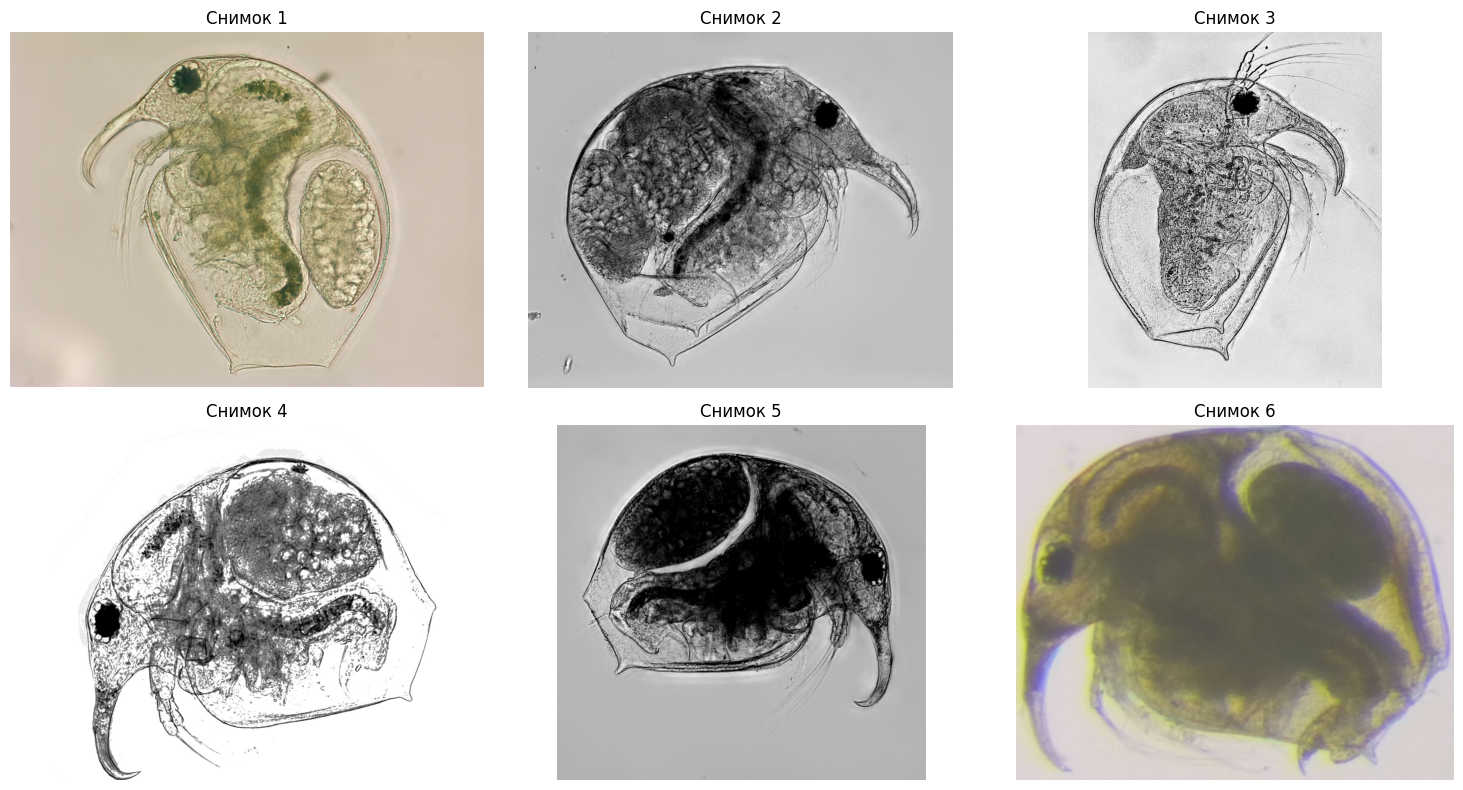

In [117]:
def show_grid(pictures, titles, columns=3):
    rows = (len(pictures) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 4 * rows),
                             squeeze=False)
    for ax, picture, title in zip(axes.flat, pictures, titles):
        if picture.ndim == 2:
            ax.imshow(picture, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(picture, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    for ax in axes.flat:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_grid(images, [f"Снимок {i + 1}" for i in range(len(images))])

## 2. Базовая предобработка
**Gray** оставляет яркость. **GaussianBlur 3×3** слегка подавляет мелкий шум.
**CLAHE** усиливает контраст в локальных областях; `clipLimit=2.0` ограничивает
усиление, а `tileGridSize=(8, 8)` задаёт сетку областей.
Маска, отражение и ручная разметка здесь не используются.

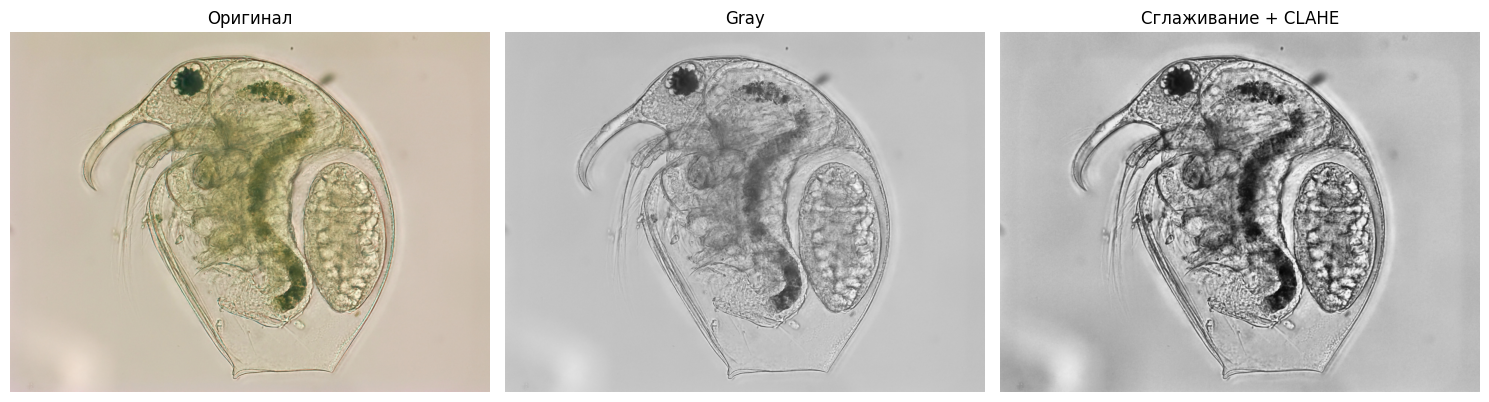

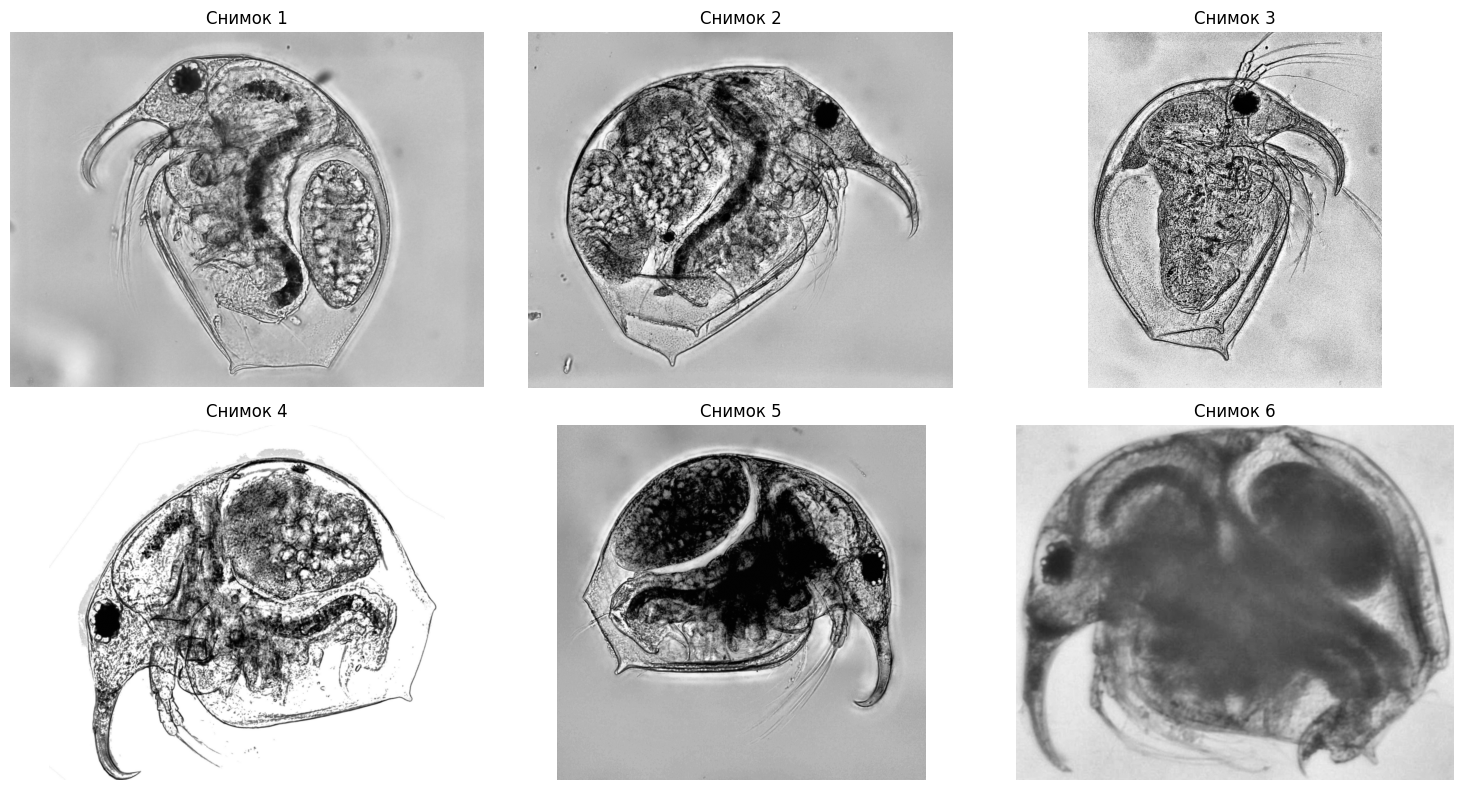

In [118]:
gray_images = []
processed = []
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

for image in images:
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    normalized = clahe.apply(blurred)
    gray_images.append(gray)
    processed.append(normalized)

show_grid([images[0], gray_images[0], processed[0]],
          ["Оригинал", "Gray", "Сглаживание + CLAHE"])
show_grid(processed, [f"Снимок {i + 1}" for i in range(len(images))])

## 3. Ключевые точки и дескрипторы SIFT
- `nfeatures` - 3000 - Лимит сохраняемых сильных точек; при равных откликах возможен небольшой избыток 
- `nOctaveLayers` - 3 - Число слоёв масштаба в октаве 
- `contrastThreshold` - 0.04 - Отбор по контрасту; снижение пропускает больше слабых деталей 
- `edgeThreshold` - 10 - Отбор вытянутых деталей; увеличение ослабляет фильтрацию 
- `sigma` - 1.6 - Начальное сглаживание SIFT 

`detectAndCompute` возвращает точки и матрицу дескрипторов — по 128 чисел на точку.

In [119]:
sift_params = dict(nfeatures=3000, nOctaveLayers=3, contrastThreshold=0.04,
                   edgeThreshold=10, sigma=1.6)
sift = cv2.SIFT_create(**sift_params)
keypoints, descriptors = [], []
for image in processed:
    points, vectors = sift.detectAndCompute(image, None)
    keypoints.append(points)
    descriptors.append(vectors)

for i, (points, vectors) in enumerate(zip(keypoints, descriptors), start=1):
    print(f"Снимок {i}: {len(points)} точек; дескрипторы: "
          f"{None if vectors is None else vectors.shape}")

Снимок 1: 3002 точек; дескрипторы: (3002, 128)
Снимок 2: 3001 точек; дескрипторы: (3001, 128)
Снимок 3: 3000 точек; дескрипторы: (3000, 128)
Снимок 4: 3001 точек; дескрипторы: (3001, 128)
Снимок 5: 3001 точек; дескрипторы: (3001, 128)
Снимок 6: 492 точек; дескрипторы: (492, 128)


Показываем **100 самых сильных точек**

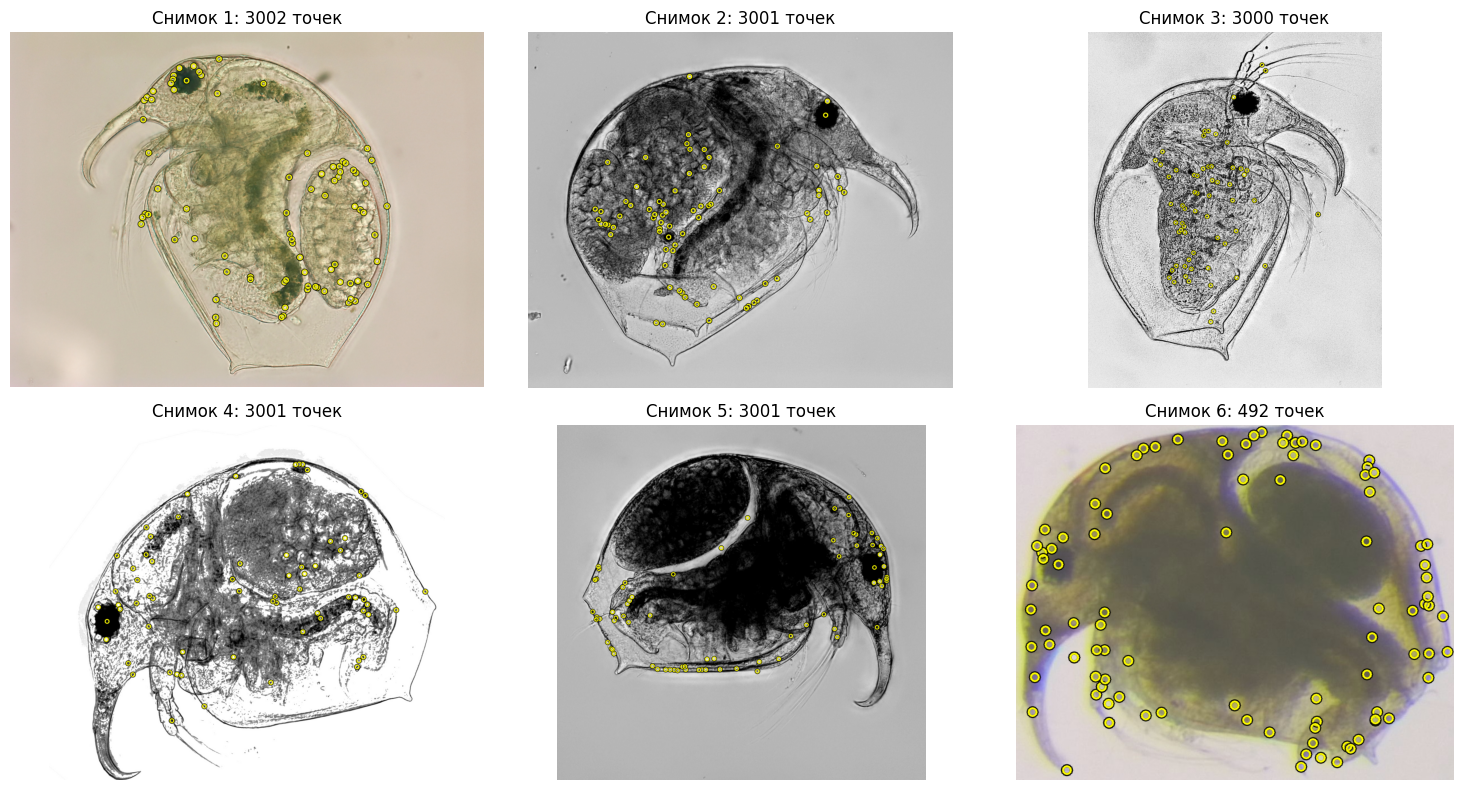

In [120]:
point_views = []
for image, points in zip(images, keypoints):
    strongest = sorted(points, key=lambda point: point.response, reverse=True)[:100]
    view = image.copy()
    for point in strongest:
        center = tuple(round(value) for value in point.pt)
        cv2.circle(view, center, 8, (0, 0, 0), 4, cv2.LINE_AA)
        cv2.circle(view, center, 7, (0, 255, 255), 2, cv2.LINE_AA)
    point_views.append(view)
show_grid(point_views, [f"Снимок {i + 1}: {len(p)} точек"
                        for i, p in enumerate(keypoints)])

## 4. Сопоставление и фильтрация
Ищем двух ближайших соседей по расстоянию L2.
**Ratio test:** `d1 < 0.8 × d2`. Если два кандидата почти одинаково близки,
выбор неоднозначен.

Затем требуем **взаимности**: точка A выбирает B, а B выбирает A.
Небольшая функция ниже нужна, потому что фильтрацию повторяем в обоих направлениях.

In [121]:
matcher = cv2.BFMatcher(cv2.NORM_L2)

def ratio_matches(source, target):
    if source is None or target is None or len(target) < 2:
        return []
    matches = []
    for neighbors in matcher.knnMatch(source, target, k=2):
        if len(neighbors) == 2:
            best, second = neighbors
            if best.distance < 0.8 * second.distance:
                matches.append(best)
    return matches

In [122]:
pair_matches, pair_stats = {}, []
for i, j in combinations(range(len(images)), 2):
    forward = ratio_matches(descriptors[i], descriptors[j])
    backward = ratio_matches(descriptors[j], descriptors[i])
    reverse_pairs = {(m.trainIdx, m.queryIdx) for m in backward}
    mutual = [m for m in forward if (m.queryIdx, m.trainIdx) in reverse_pairs]
    pair_matches[(i, j)] = sorted(mutual, key=lambda m: m.distance)
    pair_stats.append({"pair": [i + 1, j + 1], "after_ratio": len(forward),
                       "mutual": len(mutual)})

rows = ["| Пара | Ratio test (вперёд) | После взаимной проверки |", "|---|---:|---:|"]
for row in pair_stats:
    i, j = row["pair"]
    rows.append(f"| {i}–{j} | {row['after_ratio']} | {row['mutual']} |")
display(Markdown("\n".join(rows)))

| Пара | Ratio test (вперёд) | После взаимной проверки |
|---|---:|---:|
| 1–2 | 37 | 9 |
| 1–3 | 36 | 4 |
| 1–4 | 50 | 17 |
| 1–5 | 41 | 14 |
| 1–6 | 57 | 6 |
| 2–3 | 40 | 10 |
| 2–4 | 33 | 9 |
| 2–5 | 33 | 8 |
| 2–6 | 64 | 5 |
| 3–4 | 23 | 3 |
| 3–5 | 14 | 3 |
| 3–6 | 39 | 1 |
| 4–5 | 40 | 10 |
| 4–6 | 60 | 3 |
| 5–6 | 67 | 8 |

## 5. Визуализация попарных кандидатов

In [123]:
def draw_pair(i, j):
    colors = [(0, 255, 255), (255, 0, 255), (255, 255, 0),
              (0, 255, 0), (0, 140, 255), (255, 100, 100)]
    
    view = cv2.drawMatches(images[i], [], images[j], [], [], None)
    points = []
    for number, match in enumerate(pair_matches[(i, j)][:30], 1):

        x1, y1 = keypoints[i][match.queryIdx].pt
        x2, y2 = keypoints[j][match.trainIdx].pt

        a = (round(x1), round(y1))
        b = (round(x2) + images[i].shape[1], round(y2))

        color = colors[(number - 1) % len(colors)]
        cv2.line(view, a, b, (0, 0, 0), 7)
        cv2.line(view, a, b, color, 3)

        points.extend([(a, number, color), (b, number, color)])
    for (x, y), number, color in points:
        cv2.circle(view, (x, y), 11, (0, 0, 0), -1)
        cv2.circle(view, (x, y), 8, color, -1)

        label_x = min(x + 15, view.shape[1] - 45)
        label_y = max(y - 15, 30)
        
        cv2.rectangle(view, (label_x - 3, label_y - 25),
                      (label_x + 40, label_y + 6), (0, 0, 0), -1)
        cv2.putText(view, str(number), (label_x, label_y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.85, color, 2)
    return view

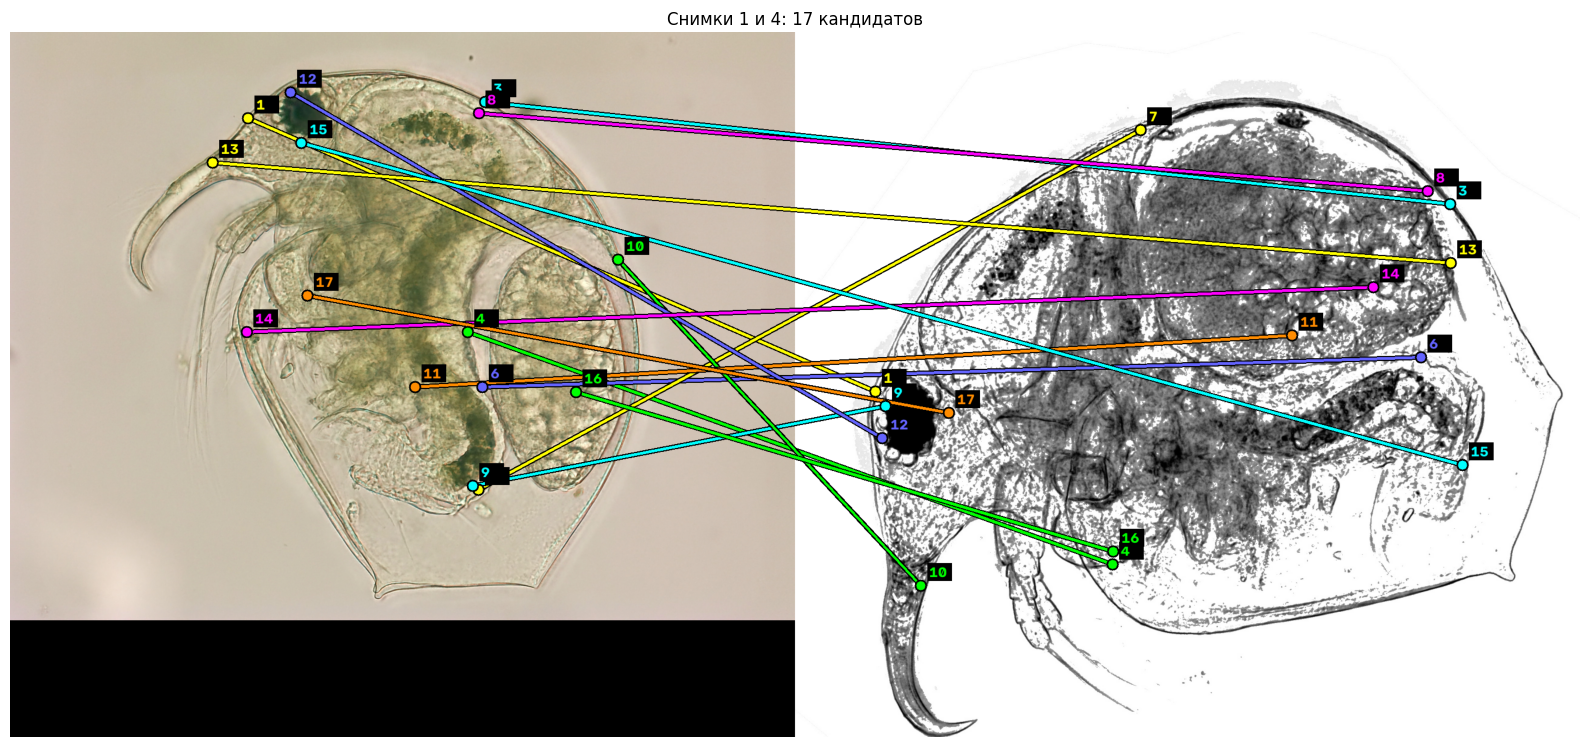

In [124]:
best_pair = max(pair_matches, key=lambda pair: len(pair_matches[pair]))
i, j = best_pair
best_view = draw_pair(i, j)
plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(best_view, cv2.COLOR_BGR2RGB))
plt.title(f"Снимки {i + 1} и {j + 1}: {len(pair_matches[best_pair])} кандидатов")
plt.axis("off")
plt.tight_layout()
plt.show()

Для текущих снимков в паре 1–4 видны ошибочные связи, в том числе между
внутренней структурой первого организма и областью глаза четвёртого.
Поэтому число линий нельзя выдавать за число верных общих анатомических точек.

Ниже показаны остальные пары с ненулевым числом кандидатов.

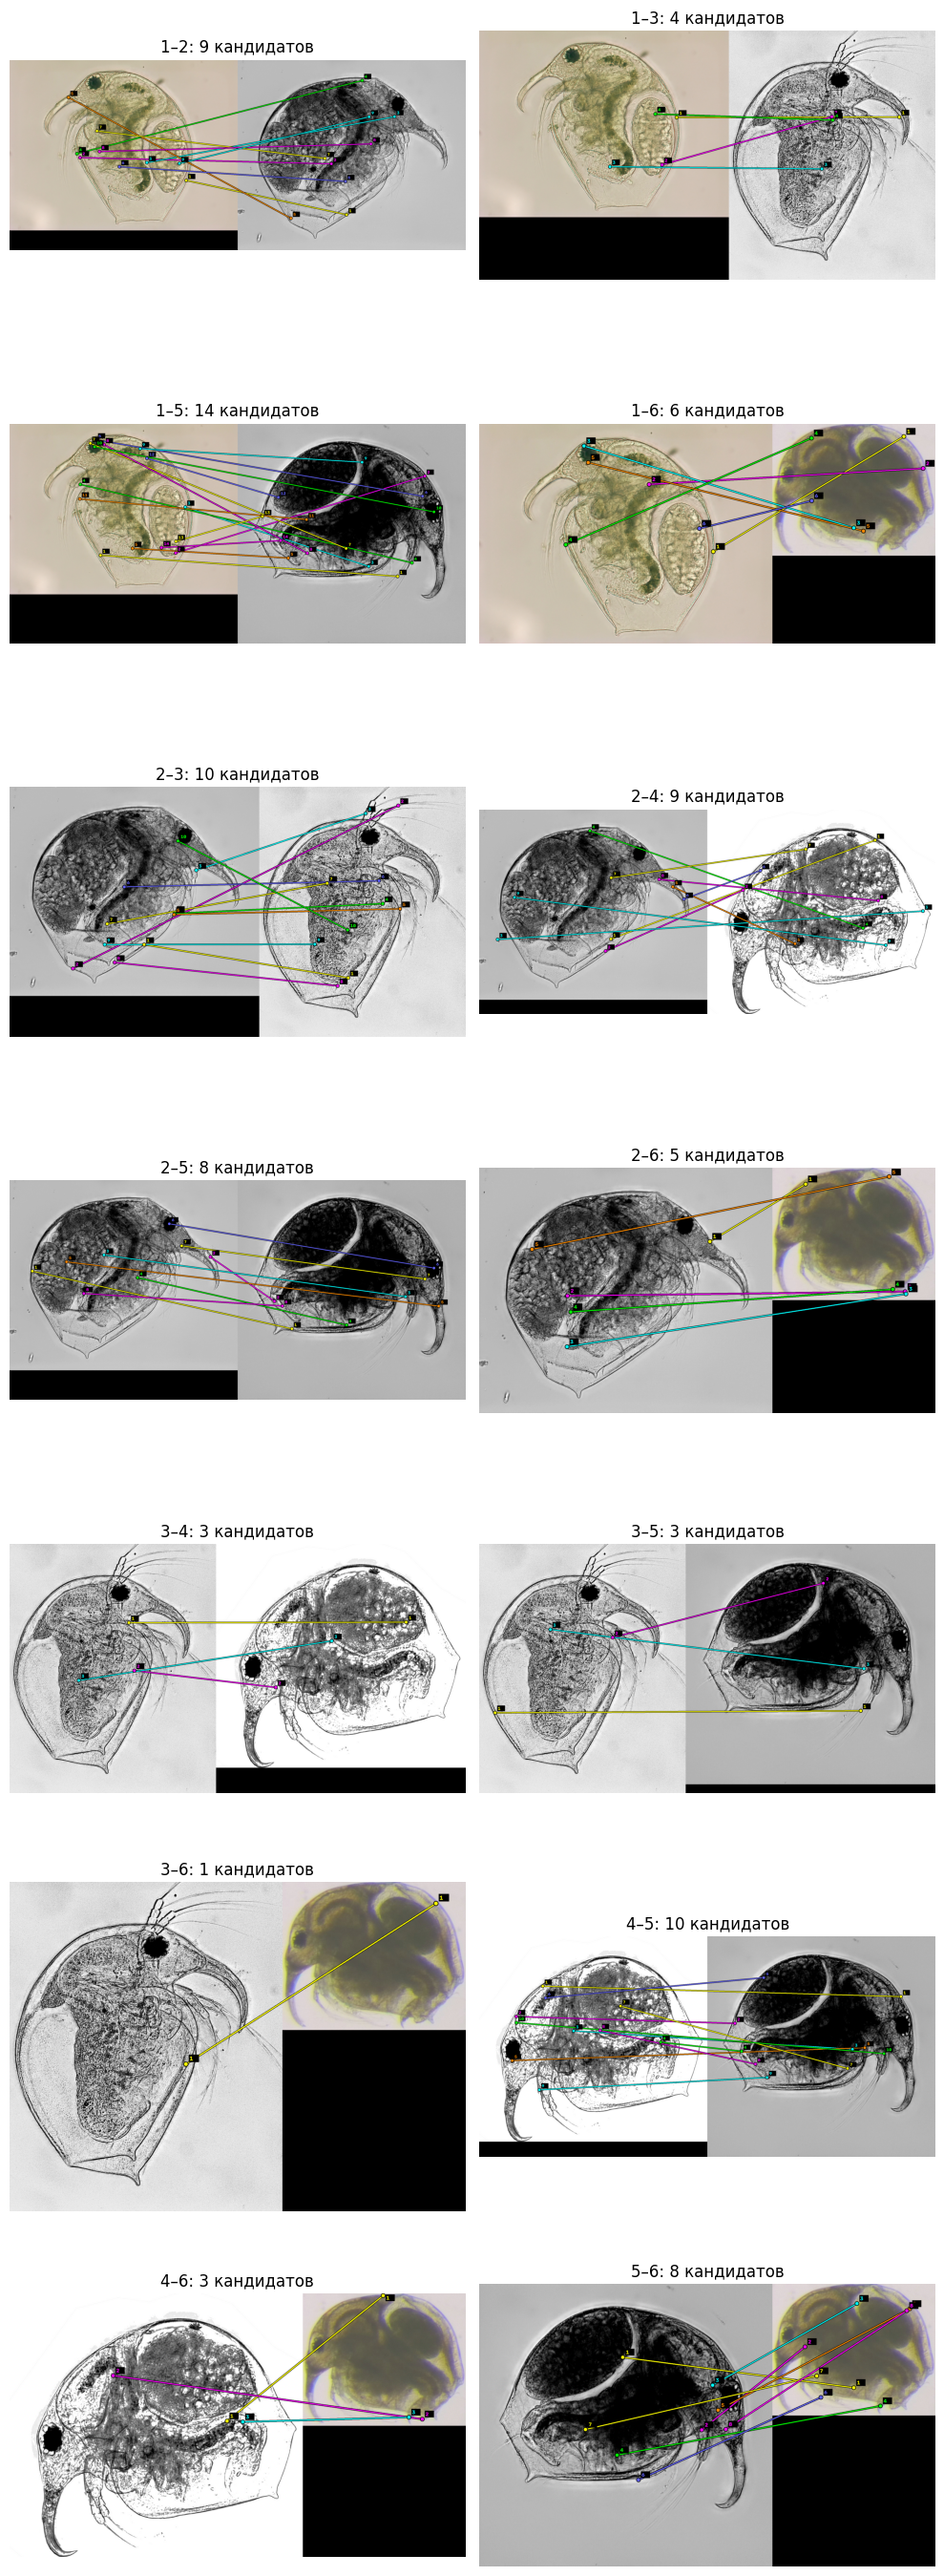

In [ ]:
pairs = [pair for pair, matches in pair_matches.items() if matches and pair != best_pair]
if pairs:
    show_grid([draw_pair(i, j) for i, j in pairs],
              [f"{i + 1}–{j + 1}: {len(pair_matches[(i, j)])} кандидатов" for i, j in pairs],
              columns=2)
else:
    print("Других пар с кандидатами нет.")

## 6. Точки, общие для всех снимков

In [126]:
mappings = {}
for pair, matches in pair_matches.items():
    mappings[pair] = {}
    for match in matches:
        mappings[pair][match.queryIdx] = match.trainIdx

candidate_tracks = []
for anchor in mappings[(0, 1)]:
    indices = [anchor]
    for other in range(1, len(images)):
        target = mappings[(0, other)].get(anchor)
        if target is None:
            break
        indices.append(target)
    if len(indices) == len(images):
        candidate_tracks.append(indices)
print("Точек с соответствием на каждом снимке:", len(candidate_tracks))

Точек с соответствием на каждом снимке: 0


In [127]:
tracks = []
for indices in candidate_tracks:
    consistent = True
    for i, j in combinations(range(len(images)), 2):
        if mappings[(i, j)].get(indices[i]) != indices[j]:
            consistent = False
            break
    if consistent:
        tracks.append(indices)
print("Общих согласованных треков:", len(tracks))

Общих согласованных треков: 0


In [ ]:
fig, axes = plt.subplots((len(images) + 2) // 3, 3, figsize=(15, 9), squeeze=False)
for i, (image, ax) in enumerate(zip(images, axes.flat)):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Снимок {i + 1}: общих треков {len(tracks)}")
    for number, indices in enumerate(tracks[:30], 1):
        x, y = keypoints[i][indices[i]].pt
        ax.plot(x, y, "yo", markersize=9, markeredgecolor="black")
        ax.annotate(str(number), (x, y), color="yellow",
                    bbox=dict(facecolor="black", pad=2))
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Итоговые выводы
- Базовая предобработка и SIFT находят множество локальных деталей. Количество около 3000
  на крупных снимках связано с установленным лимитом, а не с равной информативностью снимков.
- Попарные кандидаты найдены, но визуально среди них присутствуют ошибки.
- Для текущего набора общих согласованных точек на всех рассматриваемых снимках **не найдено**.
- По полученным совпадениям нельзя надёжно определить наиболее устойчивые части организма.
- Различия внутренних структур, ракурса, контраста и качества могут объяснять трудности.